<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Ejercicios/01-Mi-segundo-modelo-Plantilla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Mi segundo modelo
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Nombre y Apellido &bull; Fecha
            </font></p>
        </td>  
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

Este cuaderno está diseñado para practicar el entrenamiento y evaluación de un modelo de regresión lineal utilizando datos reales. Los objetivos principales son:

- Entrenar un modelo de regresión lineal.
- Evaluar el ajuste del modelo.


Del conjunto de datos disponible [aquí](https://raw.githubusercontent.com/mGalarnyk/Tutorial_Data/master/King_County/kingCountyHouseData.csv), se desea predecir la variable `price` en función de las variables `bedrooms`, `bathrooms`, `sqft_living`, `sqft_lot`, `floors`.

In [12]:
# Paquetes necesarios
import numpy as np  # Para generación de datos y operaciones numéricas
import pandas as pd  # Para manejo de datos estructurados
import matplotlib.pyplot as plt  # Para visualización de datos
from sklearn.linear_model import LinearRegression  # Para el modelo de regresión lineal
from sklearn.metrics import mean_squared_error, r2_score  # Para evaluación del modelo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, KBinsDiscretizer, OneHotEncoder
from sklearn.decomposition import PCA

---
## <font color='264CC7'> Lectura de Datos </font>


Realiza la lectura de los datos y presenta las primeras filas del conjunto de datos.

In [2]:
url = 'https://raw.githubusercontent.com/mGalarnyk/Tutorial_Data/master/King_County/kingCountyHouseData.csv'
df = pd.read_csv(url)
display(df.head())

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


---
## <font color='264CC7'> Características y etiquetas </font>

Separa las características y las etiquetas y mostrar la dimensión de cada elemento.

In [3]:
# Dividir el conjunto de datos en características y etiquetas
features = ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors']
X = df.loc[:, features]
y = df.loc[:, ['price']]

# Mostrar las dimensiones de las características y etiquetas
print('Dimensiones de las características y etiquetas:')
print('X:', X.shape)
print('y:', y.shape)

Dimensiones de las características y etiquetas:
X: (21613, 5)
y: (21613, 1)


---
## <font color='264CC7'> Conjunto de entrenamiento y prueba </font>

Divide los datos en dos conjuntos: uno para entrenamiento y otro para prueba y visualiza la dimensión de cada conjunto. Usar `random_state` igual al último número de tu cédula.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7)

Revisa la distribución de las etiquetas en los conjuntos de entrenamiento y prueba.

Resumen estadístico de entrenamiento (y_train):


,price
count,1.729000e+04
mean,5.404569e+05
std,3.680163e+05
min,7.500000e+04
25%,3.200000e+05
50%,4.500000e+05
75%,6.480000e+05
max,7.700000e+06



Resumen estadístico de prueba (y_test):


,price
count,4.323000e+03
mean,5.386134e+05
std,3.635878e+05
min,8.995000e+04
25%,3.249500e+05
50%,4.500000e+05
75%,6.350000e+05
max,6.885000e+06


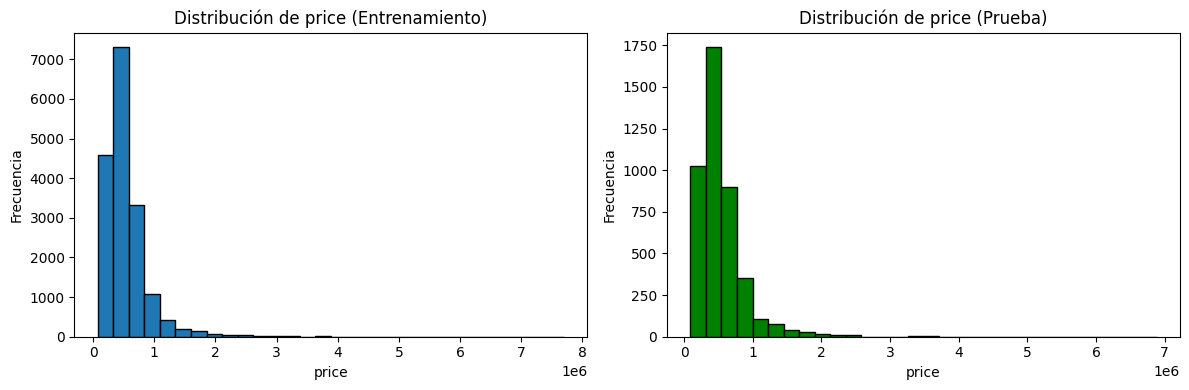

In [7]:
# Mostrar estadísticas descriptivas de las etiquetas
print("Resumen estadístico de entrenamiento (y_train):")
display(y_train.describe())

print("\nResumen estadístico de prueba (y_test):")
display(y_test.describe())

# Graficar la distribución de las etiquetas en entrenamiento y prueba
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(y_train.values.flatten(), bins=30, edgecolor='black')
plt.title('Distribución de price (Entrenamiento)')
plt.xlabel('price')
plt.ylabel('Frecuencia')

plt.subplot(1, 2, 2)
plt.hist(y_test.values.flatten(), bins=30, color='g', edgecolor='black')
plt.title('Distribución de price (Prueba)')
plt.xlabel('price')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

---
## <font color='264CC7'> Preprocesamiento de datos </font>

Decide si hace falta escalar las características para este ejemplo de regresión lineal. Si aplicas una transformación vista en clase, aprende sus parámetros solo con X_train y aplica la misma transformación a X_test, sin modificar la variable objetivo. No elijas transformaciones por su error de prueba.

In [8]:
scaler = StandardScaler()
# Ajustar con X_train y transformar X_train y X_test manteniendo el formato DataFrame
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=features,
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=features,
    index=X_test.index
)

# Mostrar las primeras filas de los datos escalados de entrenamiento
display(X_train_scaled.head())

,bedrooms,bathrooms,sqft_living,sqft_lot,floors
20046,-0.399659,0.498039,0.428216,-0.277229,0.934725
7278,-0.399659,0.498039,-0.027607,-0.110226,-0.918752
13226,0.668693,0.498039,0.775509,-0.214904,0.934725
6832,0.668693,0.498039,-0.146989,-0.239645,-0.918752
21131,0.668693,0.822753,1.025126,-0.213417,0.934725


---
## <font color='264CC7'> Entrenamiento </font>

Define un modelo de regresión lineal y entrénalo con los datos de entrenamiento.

In [9]:
#Ajustarlo con los datos de entrenamiento escalados
modelo = LinearRegression()
modelo.fit(X_train_scaled, y_train)

# Visualizar los coeficientes aprendidos
print('Parámetros del modelo entrenado:')
print('Intercepto (b_0):', modelo.intercept_[0])
print('\nCoeficientes por característica (variables estandarizadas):')
df_coeficientes = pd.DataFrame({
    'Característica': features,
    'Coeficiente': modelo.coef_[0]
})
display(df_coeficientes)

Parámetros del modelo entrenado:
Intercepto (b_0): 540456.8744939271

Coeficientes por característica (variables estandarizadas):


,Característica,Coeficiente
0,bedrooms,-54327.306193
1,bathrooms,4154.724974
2,sqft_living,289863.362222
3,sqft_lot,-17627.186518
4,floors,1078.358354


---
## <font color='264CC7'> Evaluación </font>

Realiza las predicciones con el conjunto de prueba y muestra los valores en una tabla.

In [10]:
# Predicciones del modelo sobre el conjunto de prueba
y_pred = modelo.predict(X_test_scaled)

# Comparar las predicciones con los datos de prueba
df_predicciones = pd.DataFrame({
    'Actual': y_test.values.flatten(),
    'Predicción': y_pred.flatten()
})
display(df_predicciones.head(15))

,Actual,Predicción
0,462000.0,182299.162853
1,768000.0,747813.365439
2,920000.0,688272.716229
3,263000.0,412810.903256
4,427500.0,620888.127055
5,299000.0,337675.971417
6,507250.0,627561.443445
7,385000.0,325335.112570
8,235000.0,603697.502717
9,1410000.0,871428.289717


Calcula el error cuadrático medio.

In [11]:
# Métricas de evaluación
mse = mean_squared_error(y_test, y_pred)

print('Error cuadrático medio (MSE):', mse)

Error cuadrático medio (MSE): 66216707795.69041


Registra las características utilizadas, la proporción de prueba, la semilla, el preprocesamiento elegido y el error cuadrático medio del modelo. Interpreta el resultado en unidades cuadradas del precio y explica sus limitaciones. No se exige comparar escalados ni elegir el que produzca el menor error de prueba.

Para el modelo se utilizaron las características bedrooms, bathrooms, sqft_living, sqft_lot y floors para predecir price, con una proporción de prueba del 20% (test_size=0.2) y semilla random_state=7. En el preprocesamiento se aplicó StandardScaler ajustado solo con X_train y aplicado a X_test sin alterar y, para igualar las escalas de las variables sin filtrar datos de prueba. Se obtuvo un MSE de 66216707795.69 ($\approx 6.62 \times 10^{10}$), al expresarse en dólares al cuadrado ($\text{USD}^2$), la cifra es muy alta y no se interpreta directamente en la escala real del dinero (su raíz cuadrada equivale a unos $\$257,326\text{ USD}$ de error promedio). Sus principales limitaciones son que penaliza en exceso las casas más caras por elevar los errores al cuadrado y que el modelo omite factores clave como la ubicación o el estado de la vivienda.

Escribe una conclusión sobre el flujo implementado: qué aprendió el modelo de entrenamiento, qué información aporta prueba y qué deberías reservar para validación si quisieras comparar alternativas.

###Conclusión
Con el flujo implementado se logró preparar los datos y entrenar un modelo de regresión lineal capaz de aprender la relación entre las características físicas de las casas y su precio de venta. Asimismo, se aplicó correctamente el preprocesamiento aprendiendo los parámetros del escalador solo con el conjunto de entrenamiento y transformando el de prueba sin volver a ajustarlo, evitando así filtrar información. La partición de prueba y el cálculo del MSE permitieron medir qué tanto se alejan las predicciones de los valores reales frente a observaciones nuevas. Si más adelante se quisieran comparar distintas alternativas o configuraciones del modelo, se deberían reservar datos de validación para tomar esa decisión y mantener el conjunto de prueba únicamente para la evaluación final.